# Fire Detection using Hugging Face

This notebook demonstrates how to load a pre-trained Vision Transformer model from Hugging Face for fire detection.

In [1]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
from PIL import Image
import torch
from IPython.display import display

c:\Users\ABHIROOP\anaconda3\envs\chatbot\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Model
We use `prithivMLmods/Fire-Detection-Siglip2` which categorizes into Fire, Normal, and Smoke.

In [2]:
model_name = "prithivMLmods/Fire-Detection-Siglip2"
processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModelForImageClassification.from_pretrained(model_name)

Loading weights: 100%|██████████| 210/210 [00:00<00:00, 3293.73it/s]


## Inference Function
Create a function to predict fire vs no-fire.

In [3]:
def detect_fire(image_path):
    # Load your input image
    image = Image.open(image_path).convert("RGB")
    
    # Preprocess the image for the model
    inputs = processor(images=image, return_tensors="pt")
    
    # Run the image through the model (Inference)
    with torch.no_grad():
        outputs = model(**inputs)
        
    # Get the predicted class
    logits = outputs.logits
    predicted_class_idx = logits.argmax(-1).item()
    
    # Print the result
    predicted_label = model.config.id2label[predicted_class_idx]
    
    # Display image and prediction
    display(image)
    print(f"Prediction: {predicted_label}")
    return predicted_label

## Save Model
Save the processor and model locally for backend use.

In [4]:
save_directory = "./saved_fire_model"
processor.save_pretrained(save_directory)
model.save_pretrained(save_directory)
print(f"Model and processor saved to {save_directory}")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.57it/s]

Model and processor saved to ./saved_fire_model


## Testing with Dataset
Test on samples from folder '0' (No fire) and '1' (Fire).

In [5]:
import os

base_path = "D:/Accident/Fire-Detection"

def test_folder(folder_name):
    folder_path = os.path.join(base_path, folder_name)
    if not os.path.exists(folder_path):
        print(f"Folder not found: {folder_path}")
        return
        
    images = [img for img in os.listdir(folder_path) if img.endswith((".jpg", ".png", ".jpeg"))]
    if not images:
        print(f"No images found in {folder_path}")
        return
        
    print(f"\n--- Testing images from folder {folder_name} ---")
    for img_name in images[:3]:
        img_path = os.path.join(folder_path, img_name)
        detect_fire(img_path)


--- Testing images from folder 0 ---


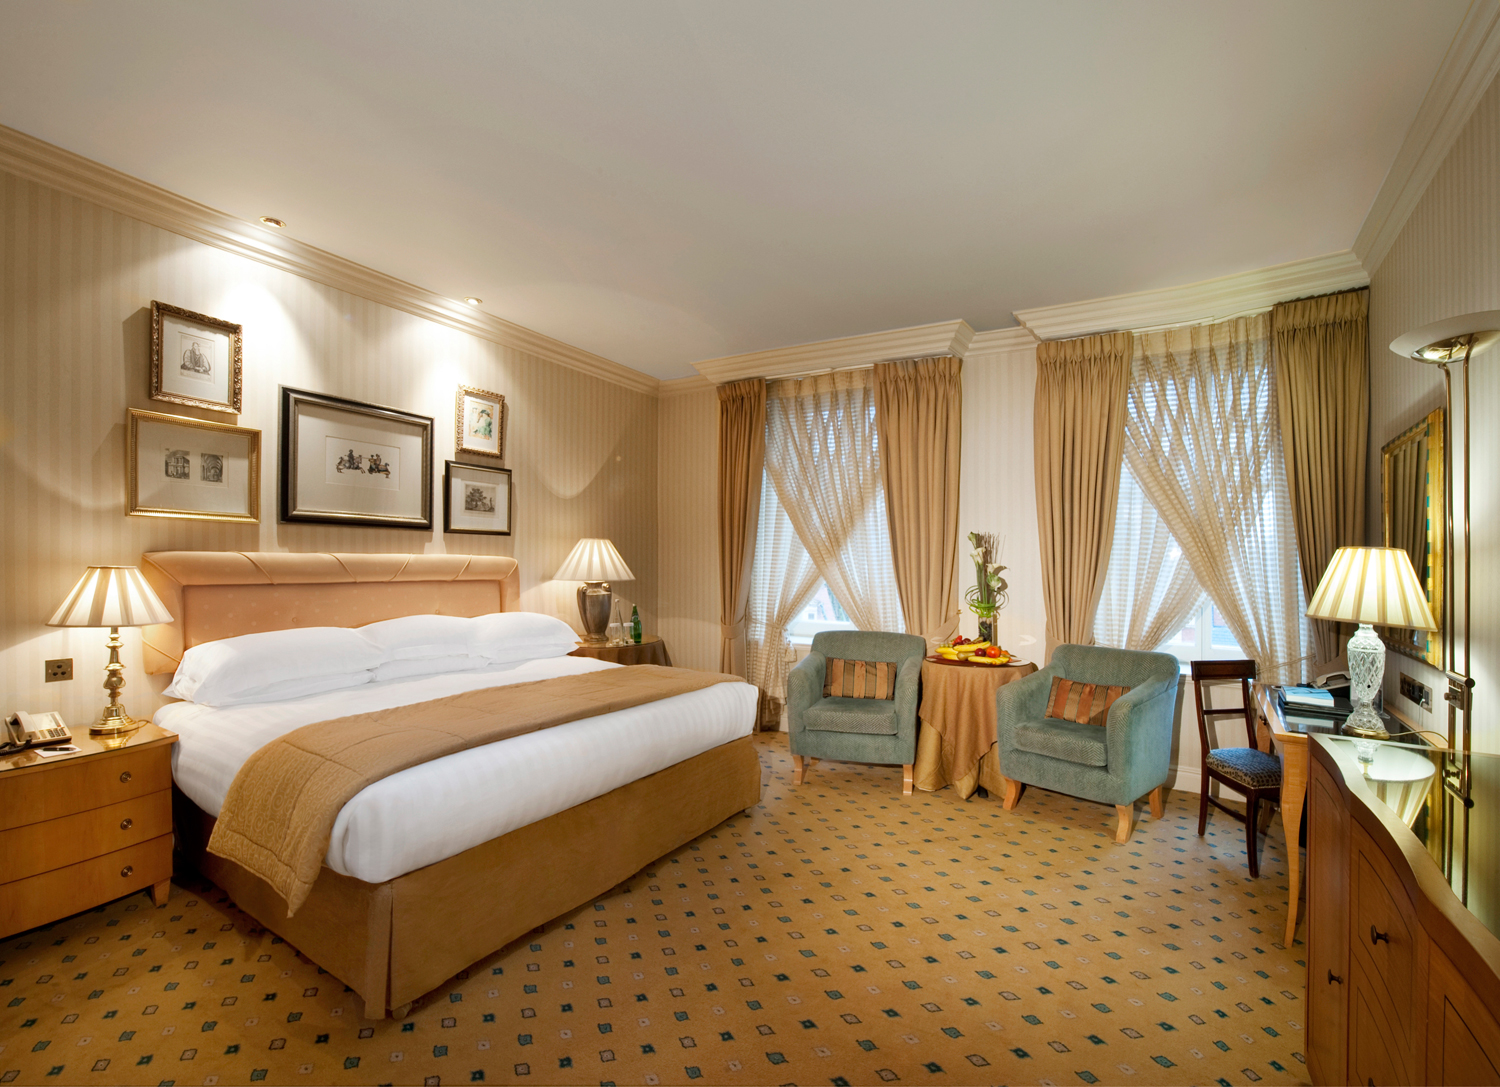

Prediction: normal


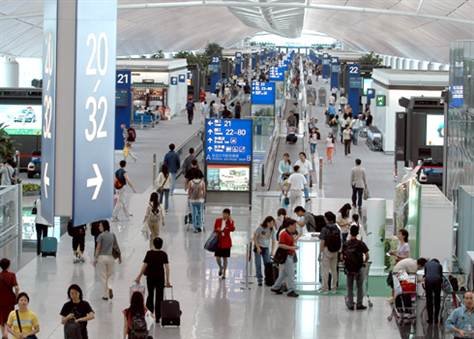

Prediction: normal


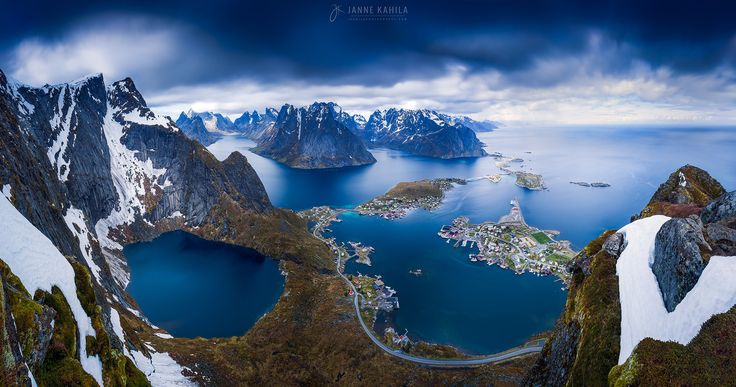

Prediction: normal

--- Testing images from folder 1 ---


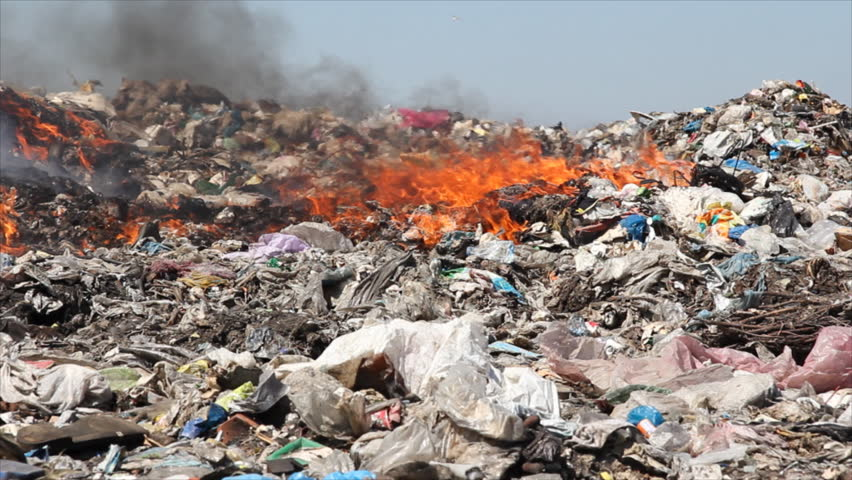

Prediction: fire


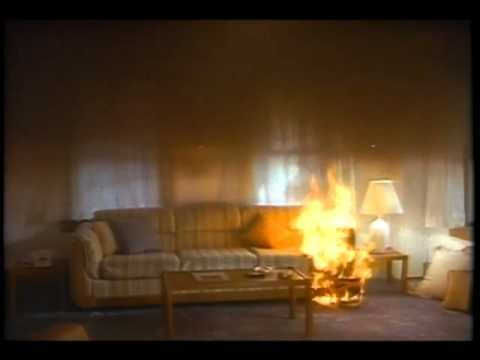

Prediction: fire


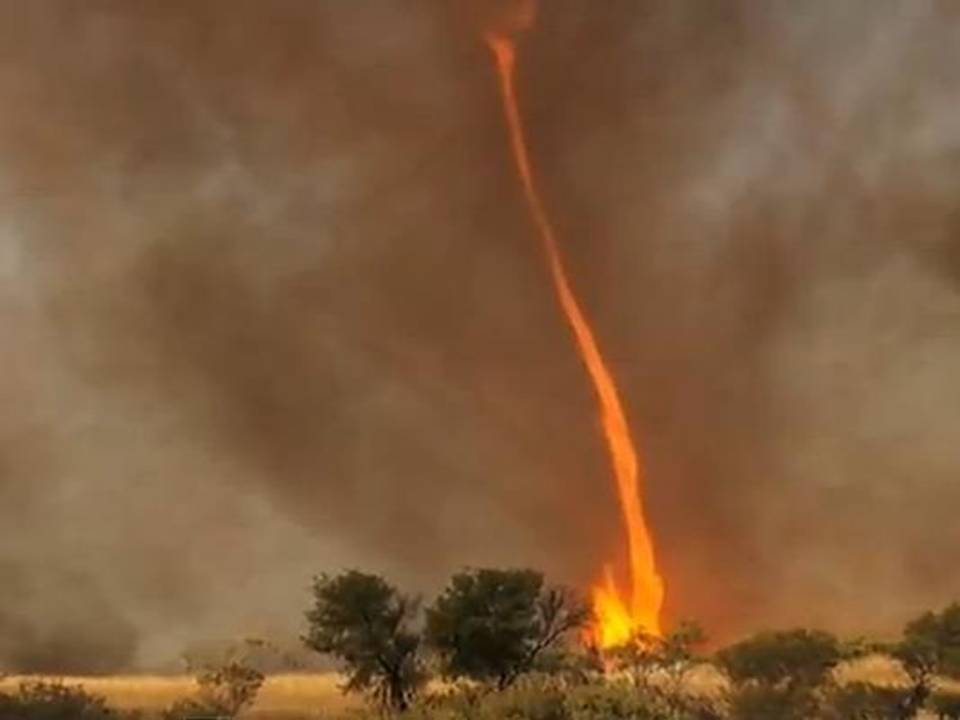

Prediction: fire


In [6]:
# Test No Fire (0)
test_folder("0")

# Test Fire (1)
test_folder("1")